# Pięć arkuszy: wyniki

Arkusz `6.148.12.04.2` i jego cztery sąsiednie arkusze (północ, południe, wschód, zachód), razem 2 km². Ten sam potok co w `proof_of_concept.ipynb`:
świadek (Haiku 5.5) opisuje budynek ze zdjęć i rekordu BDOT10k, rubryka z literatury zamienia opis na liczbę mieszkańców,
pętla uzgadnia go ze spisem, a szperacz szuka w sieci liczby miejsc albo mieszkań dla najwyżej 4 budynków z każdego arkusza.
Sumy porównujemy ze spisem NSP 2021 w kwadratach 125 m, które leżą w całości na arkuszach.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]
import re

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from shapely.geometry import box

from agenci import PRZEBIEGI
from agenci.ewaluacja import ocena_kwadratow, podsumowanie, porownaj_sumy, sumy_kwadratow, wczytaj
from agenci.statystyka import budynki_w_kwadratach, kompletne_kwadraty
from ortofoto.arkusze import ARKUSZE, podklad, zasieg
from ortofoto.budynki import wczytaj_budynki

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
NIEBIESKI = LinearSegmentedColormap.from_list("niebieski", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
TUSZ, SZARY, POMARANCZ = "#333333", "#9a9a9a", "#eb6834"

def tys(x):
    return f"{x:,.0f}".replace(",", " ")

def po_polsku(tekst):  # przecinek dziesiętny w tekście dla czytelnika
    return re.sub(r"(\d)\.(\d)", r"\1,\2", tekst)

bud = wczytaj_budynki()
miasto, kw = budynki_w_kwadratach(zasieg())
arkusze = pd.Series({src.name.split("_")[-2]: box(*src.bounds) for src in ARKUSZE["N"]})
bud["arkusz"] = [next(g for g, a in arkusze.items() if c.within(a)) for c in bud.centroid]
wynik = wczytaj("piec_arkuszy_haiku").set_index("budynek")
szperacz = wczytaj("piec_arkuszy_haiku_szperacz").set_index("budynek")
BDOT = wczytaj("piec_arkuszy_objetosc_bdot")

## Obszar

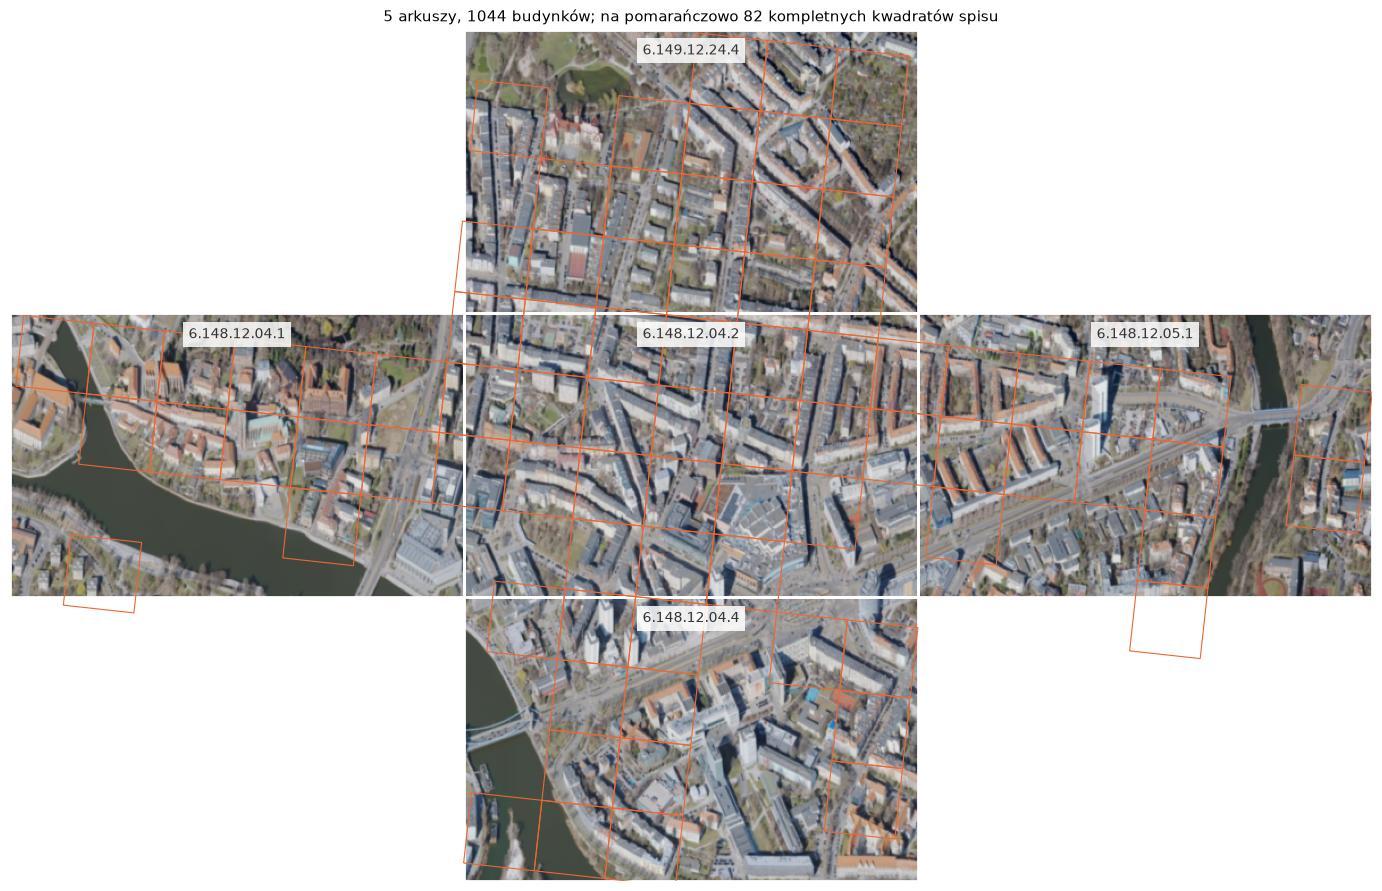

,budynki,mieszkalne_bdot,z_adresem,wysokosc_lidar
arkusz,,,,
6.148.12.04.1,117,50,66,115
6.148.12.04.2,341,248,291,340
6.148.12.04.4,146,75,112,146
6.148.12.05.1,193,111,154,193
6.149.12.24.4,247,206,223,245
razem,1044,690,846,1039


In [2]:
x0, y0, x1, y1 = zasieg().bounds
img, ext = podklad(zasieg().bounds, 2.0)
fig, ax = plt.subplots(figsize=(14, 8.8), layout="constrained")
ax.imshow(img, extent=ext)
for g, a in arkusze.items():
    ax.plot(*a.exterior.xy, color="white", lw=2)
    ax.text(a.centroid.x, a.bounds[3] - 25, g, ha="center", va="top", color=TUSZ, fontsize=10, bbox=dict(fc="white", ec="none", alpha=0.85))
kody = kompletne_kwadraty(miasto, bud.index)
kw.loc[kody].boundary.plot(ax=ax, color=POMARANCZ, lw=0.8)
ax.set(xlim=(x0, x1), ylim=(y0, y1), title=f"5 arkuszy, {len(bud)} budynków; na pomarańczowo {len(kody)} kompletnych kwadratów spisu")
ax.set_axis_off()
plt.show()

t = bud.groupby("arkusz").agg(budynki=("funkcja", "size"), mieszkalne_bdot=("mieszkalny_bdot", "sum"),
                              z_adresem=("addr:street", lambda s: s.notna().sum()), wysokosc_lidar=("zrodlo_h", lambda s: (s == "LiDAR").sum()))
t.loc["razem"] = t.sum()
t

## Wszystkie przebiegi

`kw_spearman` to zgodność kolejności kwadratów ze spisem, `kw_wape` to błąd rozkładu ludzi po przeskalowaniu sumy do spisu (mniej = lepiej);
`_lo` i `_hi` to przedział 95%. Pętlę oceniamy na stanie sprzed uzgadniania, bo po nim wynik zna sumy spisu.

In [3]:
p = podsumowanie()
p = p[p.index.str.startswith("piec_arkuszy")]
p[["budynki", "bledy", "usd", "suma_mieszkancow", "mieszk_f1", "n_kwadratow", "kw_spearman", "kw_spearman_lo", "kw_spearman_hi",
   "kw_wape", "kw_wape_lo", "kw_wape_hi"]].round(3)

,budynki,bledy,usd,suma_mieszkancow,mieszk_f1,n_kwadratow,kw_spearman,kw_spearman_lo,kw_spearman_hi,kw_wape,kw_wape_lo,kw_wape_hi
przebieg,,,,,,,,,,,,
piec_arkuszy_haiku,1044,0,0.914,27504.762,0.970,82,0.856,0.754,0.925,0.284,0.206,0.391
piec_arkuszy_haiku_szperacz,1044,0,1.356,28321.247,0.970,82,0.819,0.685,0.910,0.313,0.220,0.437
piec_arkuszy_objetosc,1044,0,0.000,NaN,0.794,82,0.514,0.319,0.674,0.592,0.453,0.742
piec_arkuszy_objetosc_bdot,1044,0,0.000,NaN,1.000,82,0.893,0.820,0.930,0.289,0.223,0.363


## Szacunek na budynek

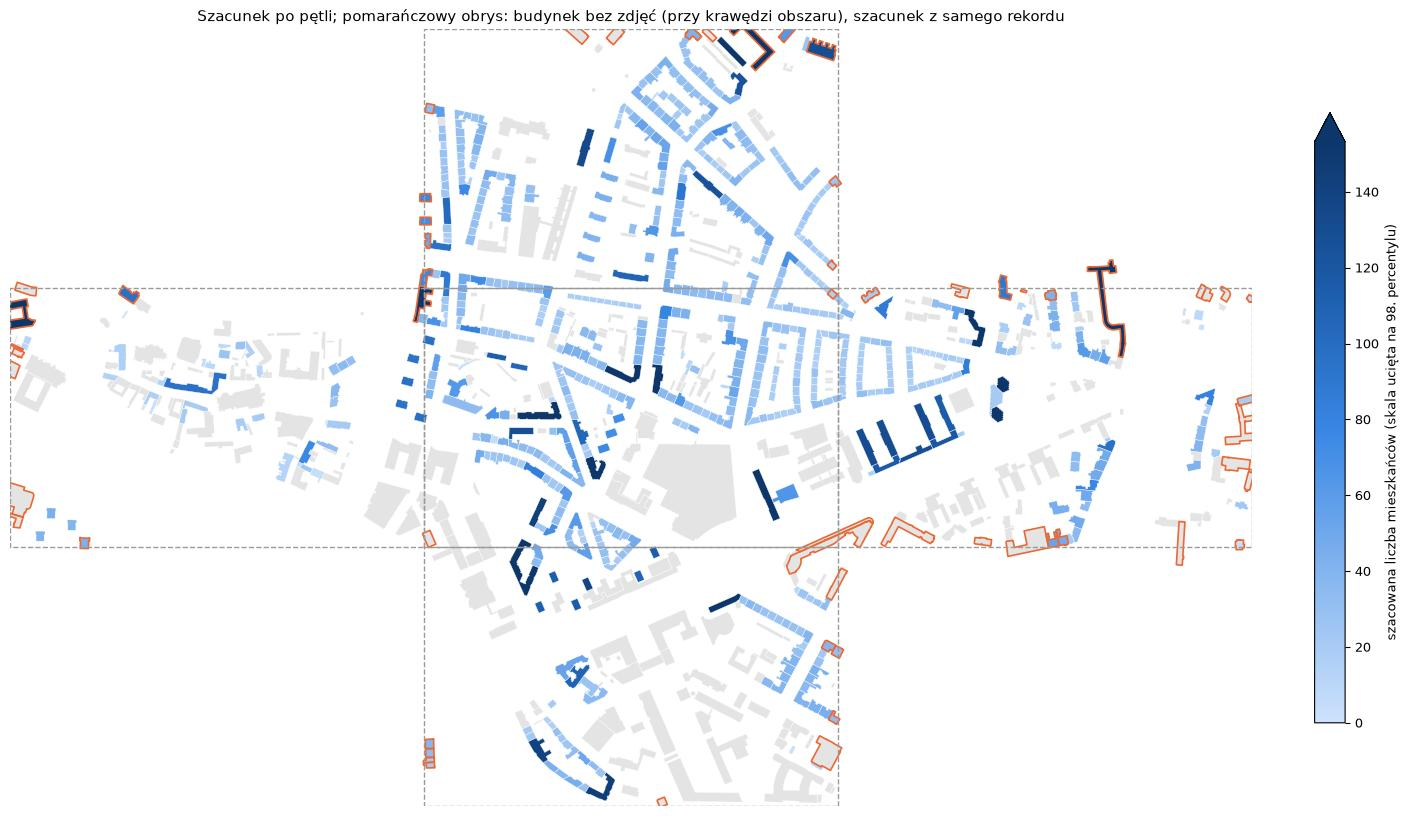

,budynki_zamieszkane,mieszkancy
arkusz,,
6.148.12.04.1,46.0,1804.0
6.148.12.04.2,247.0,8944.0
6.148.12.04.4,79.0,3726.0
6.148.12.05.1,119.0,5184.0
6.149.12.24.4,206.0,7847.0
razem,697.0,27505.0


In [4]:
mapa = bud.join(wynik[["mieszkancy", "liczba_widokow"]])
fig, ax = plt.subplots(figsize=(14, 8.8), layout="constrained")
mapa[mapa.mieszkancy.fillna(0) == 0].plot(ax=ax, color="#e4e4e4", edgecolor="white", linewidth=0.3)
zam = mapa[mapa.mieszkancy > 0]
zam.plot(ax=ax, column="mieszkancy", cmap=NIEBIESKI, vmin=0, vmax=zam.mieszkancy.quantile(0.98), edgecolor="white", linewidth=0.3,
         legend=True, legend_kwds={"label": "szacowana liczba mieszkańców (skala ucięta na 98. percentylu)", "shrink": 0.7})
mapa[mapa.liczba_widokow == 0].boundary.plot(ax=ax, color=POMARANCZ, linewidth=1.2)
for a in arkusze:
    ax.plot(*a.exterior.xy, color=SZARY, lw=1, ls="--")
ax.set(xlim=(x0, x1), ylim=(y0, y1), title="Szacunek po pętli; pomarańczowy obrys: budynek bez zdjęć (przy krawędzi obszaru), szacunek z samego rekordu")
ax.set_axis_off()
plt.show()

na_arkusz = mapa.groupby("arkusz").agg(budynki_zamieszkane=("mieszkancy", lambda s: (s > 0).sum()), mieszkancy=("mieszkancy", "sum"))
na_arkusz.loc["razem"] = na_arkusz.sum()
na_arkusz.round(0)

## Zgodność ze spisem w kwadratach

Każdy punkt to kwadrat 125 m leżący w całości na arkuszach. Szacunek jest przeskalowany do sumy spisu, więc wykres pokazuje rozkład, nie poziom.

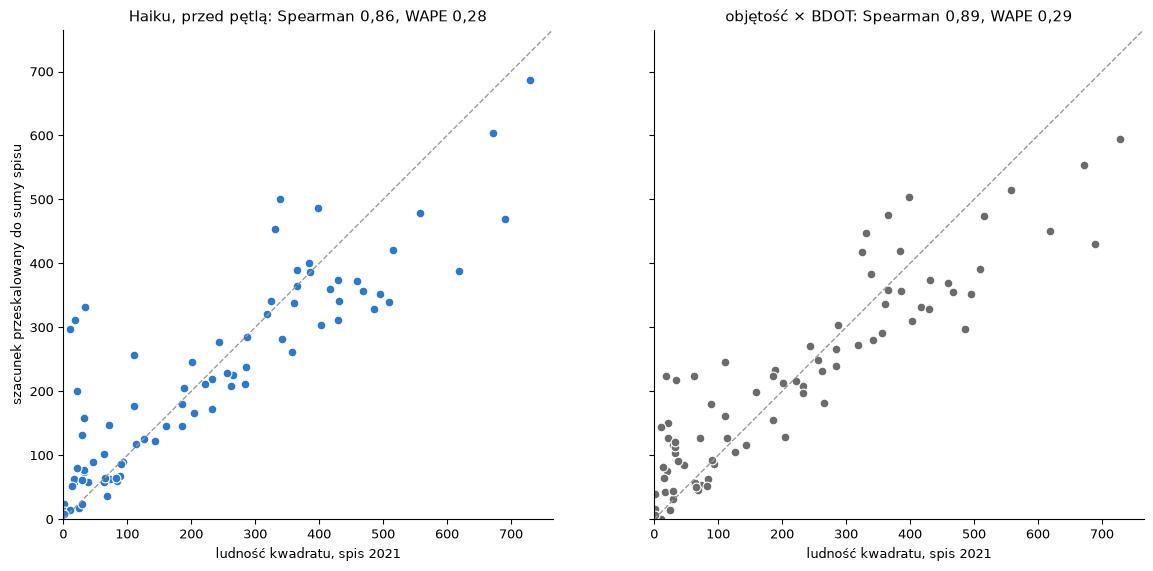

**Haiku przed pętlą minus objętość × BDOT** na 82 kwadratach: Spearman -0,04 [-0,10; +0,01], WAPE -0,01 [-0,05; +0,05].

**Poziom:** spis 18 218 os., szacunek 24 250 os. (+33%).

In [5]:
PRED = wynik.reset_index()
fig, osie = plt.subplots(1, 2, figsize=(12, 5.6), sharex=True, sharey=True, layout="constrained")
for ax, (podpis, pred, kol, kolor) in zip(osie, [("Haiku, przed pętlą", PRED, "mieszkancy_r0", "#2a78d6"), ("objętość × BDOT", BDOT, None, "#6b6b6b")]):
    suma, ref = sumy_kwadratow(pred, miasto, kw, kol)
    s = suma * ref.sum() / suma.sum()
    g = 1.05 * max(s.max(), ref.max())
    ax.plot([0, g], [0, g], color=SZARY, ls="--", lw=1)
    ax.scatter(ref, s, s=40, color=kolor, edgecolor="white", linewidth=0.8)
    o = ocena_kwadratow(pred, miasto, kw, kol)
    ax.set(title=po_polsku(f"{podpis}: Spearman {o['kw_spearman']:.2f}, WAPE {o['kw_wape']:.2f}"), xlabel="ludność kwadratu, spis 2021",
           xlim=(0, g), ylim=(0, g), aspect="equal")
osie[0].set_ylabel("szacunek przeskalowany do sumy spisu")
plt.show()

a, ref = sumy_kwadratow(PRED, miasto, kw, "mieszkancy_r0")
b, _ = sumy_kwadratow(BDOT, miasto, kw)
d = porownaj_sumy(a, b, ref)
display(Markdown(po_polsku(f"**Haiku przed pętlą minus objętość × BDOT** na {d['n']} kwadratach: Spearman {d['d_spearman']:+.2f} [{d['d_spearman_lo']:+.2f}; {d['d_spearman_hi']:+.2f}], "
                 f"WAPE {d['d_wape']:+.2f} [{d['d_wape_lo']:+.2f}; {d['d_wape_hi']:+.2f}].\n\n**Poziom:** spis {tys(ref.sum())} os., szacunek {tys(a.sum())} os. "
                 f"({a.sum() / ref.sum() - 1:+.0%}).")))

## Pętla

In [6]:
bilanse = pd.read_csv(PRZEBIEGI / "piec_arkuszy_haiku__bilans.csv")
dialog = pd.read_csv(PRZEBIEGI / "piec_arkuszy_haiku__dialog.csv")
flagi = bilanse.groupby("runda").flaga.sum().astype(int)
display(Markdown(f"**Flagi rozjazdu po rundach:** {', '.join(f'runda {r}: {f}' for r, f in flagi.items())} (na {bilanse.kod.nunique()} kwadratów). "
                 f"Agent zapytał o {int(wynik.dopytany.sum())} budynków, świadek zmienił {int(wynik.zmieniony.sum())}. "
                 f"Suma na 5 arkuszach: {tys(wynik.mieszkancy_r0.sum())} przed pętlą, {tys(wynik.mieszkancy.sum())} po niej."))
zmiany = dialog[dialog.rodzaj == "pytanie"].dropna(subset=["zmiana"])
zmiany[["budynek", "atrybut", "zmiana", "mieszkancy_przed", "mieszkancy_po"]].round(0)

**Flagi rozjazdu po rundach:** runda 0: 21, runda 1: 21, runda 2: 21 (na 82 kwadratów). Agent zapytał o 12 budynków, świadek zmienił 4. Suma na 5 arkuszach: 27 580 przed pętlą, 27 505 po niej.

,budynek,atrybut,zmiana,mieszkancy_przed,mieszkancy_po
18,2881C5D6-6907-CEB0-E053-CC2BA8C034D4,udzial_mieszkalny,udzial_mieszkalny: 0.9 -> 0.4,81.0,36.0
20,5ed93b5e-0615-4ae8-922b-27fb9a9ed68f,udzial_mieszkalny,udzial_mieszkalny: 0.95 -> 0.9,384.0,364.0
47,2881C5D6-75DC-CEB0-E053-CC2BA8C034D4,typ,udzial_mieszkalny: 0.6 -> 0.5,24.0,20.0
49,2881C5D6-780B-CEB0-E053-CC2BA8C034D4,udzial_mieszkalny,udzial_mieszkalny: 0.95 -> 0.9,118.0,112.0


## Szperacz

Dla najwyżej 4 budynków z każdego arkusza (najpierw zamieszkanie zbiorowe, potem największe szacunki) model z wyszukiwarką dostaje adresy z punktów
adresowych OSM i rekord BDOT10k i szuka liczby miejsc albo mieszkań. Liczba mieszkań razy 1,71 osoby (GUS, Wrocław 2024) zastępuje szacunek ze wzoru.

In [7]:
s = szperacz[szperacz.szukany == True].join(bud[["arkusz", "funkcja", "adresy"]])
display(Markdown(f"**Szperacz sprawdził {len(s)} budynków i znalazł liczbę dla {int((s.znalezione != 'brak').sum())}.** "
                 f"Suma tych budynków: {tys(s.mieszkancy_wzor.sum())} os. ze wzoru, {tys(s.mieszkancy.sum())} os. po szukaniu."))
pd.set_option("display.max_colwidth", 90)
s[["arkusz", "funkcja", "adresy", "mieszkancy_wzor", "znalezione", "liczba_z_sieci", "mieszkancy", "zrodlo", "cytat"]].round(0).reset_index(drop=True)

**Szperacz sprawdził 20 budynków i znalazł liczbę dla 6.** Suma tych budynków: 2 755 os. ze wzoru, 3 497 os. po szukaniu.

,arkusz,funkcja,adresy,mieszkancy_wzor,znalezione,liczba_z_sieci,mieszkancy,zrodlo,cytat
0,6.148.12.04.4,placówka opiekuńczo-wychowawcza,plac Grunwaldzki 3c,81.0,brak,0.0,81.0,NaN,Szukano liczby miejsc noclegowych lub mieszkań dla budynku pl. Grunwaldzki 3c we Wrocł...
1,6.148.12.04.2,dom studencki,Piastowska 1,322.0,miejsca,802.0,802.0,https://uwr.edu.pl/en/student-houses/addresses/,Hall of residence „Dwudziestolatka” Street: Piastowska 1 ... Capacity: 802 Rooms with ...
2,6.149.12.24.4,dom studencki,NaN,134.0,miejsca,360.0,360.0,https://drugidom.pwr.edu.pl/uploads/wykaz_domow_studenckich.pdf,"DS T-4""Czworak"" ul. Górnickiego 22 240 360 120 120 120 240 - -"
3,6.149.12.24.4,dom studencki,NaN,55.0,brak,0.0,55.0,NaN,Szukałem liczby miejsc noclegowych w Domu Studenckim T-6 Alcatraz (Mikołaja Reja 54-56...
4,6.148.12.04.2,dom studencki,Piastowska 1a,65.0,brak,0.0,65.0,NaN,Szukałem liczby miejsc dla ul. Piastowska 1a. Znalazłem tylko dane dla sąsiedniego Dom...
5,6.148.12.05.1,dom studencki,NaN,131.0,brak,0.0,131.0,NaN,"Szukano liczby miejsc w DS T-3 ""Straszny Dwór"" (Grunwaldzka 61, PWr). Znalezione stron..."
6,6.148.12.05.1,dom studencki,Sopocka 23,292.0,miejsca,336.0,336.0,https://upwr.edu.pl/akademiki/ds-labirynt,"Dom Studencki Labirynt posiada: 336 miejsc w tym: 33 pokoje jednoosobowe, 78 pokoi dwu..."
7,6.148.12.04.2,klasztor,NaN,34.0,brak,0.0,34.0,NaN,Szukano liczby miejsc noclegowych dla klasztoru przy ul. Piwnej 2-6 we Wrocławiu (Zgro...
8,6.148.12.04.4,klasztor,plac Grunwaldzki 3,53.0,brak,0.0,53.0,NaN,Szukałem liczby miejsc lub mieszkań w budynku pl. Grunwaldzki 3 we Wrocławiu i nie zna...
9,6.148.12.04.1,klasztor,NaN,32.0,brak,0.0,32.0,NaN,Szukano liczby miejsc noclegowych w klasztorze Sióstr św. Elżbiety przy ul. Świętego J...


## Walidacja na SRLM

SRLM to szacowana rzeczywista liczba mieszkańców w rejonach komunikacyjnych (raport UWr dla UMW, stan na 31.12.2022). Liczy też
niezameldowanych, więc dla całego miasta jest o ok. 33% wyższy od NSP 2021. Żaden agent go nie widzi; oceniamy rejony, w których
co najmniej 95% powierzchni mieszkalnej z BDOT10k ma predykcję. Baseline objętość × BDOT dostaje ludność NSP rozłożoną wg objętości,
a `nsp_2021` to sam spis rozdzielony na rejony. Przy kilku rejonach to sprawdzenie, że ocena działa, a nie wynik.

In [8]:
from agenci.ewaluacja import podsumowanie_srlm
from agenci.srlm import wczytaj_srlm

miary, rejony = podsumowanie_srlm()
miary = miary[miary.index.get_level_values("przebieg").str.startswith("piec_arkuszy")]
display(miary.round(3))
t = rejony.xs(("piec_arkuszy_haiku", "mieszkancy_r0"), level=("przebieg", "kolumna"))
b = rejony.xs(("piec_arkuszy_objetosc_bdot", "objetosc_m3"), level=("przebieg", "kolumna"))
t.assign(baseline=b.suma)[["nazwa", "srlm", "suma", "baseline", "nsp", "pokrycie"]].round(2).rename(columns={"suma": "haiku_przed_petla"})

n_rejonow     srlm   szacunek  \
przebieg                    kolumna                                        
piec_arkuszy_haiku          mieszkancy_r0          5  20010.0  17096.910   
                            nsp_2021               5  20010.0  12155.955   
                            mieszkancy             5  20010.0  17025.550   
piec_arkuszy_haiku_szperacz mieszkancy             5  20010.0  17164.051   
                            nsp_2021               5  20010.0  12155.955   
piec_arkuszy_objetosc       objetosc_m3            5  20010.0  13388.558   
                            nsp_2021               5  20010.0  12155.955   
piec_arkuszy_objetosc_bdot  objetosc_m3            5  20010.0  12310.578   
                            nsp_2021               5  20010.0  12155.955   

                                           poziom  spearman   wape  
przebieg                    kolumna                                 
piec_arkuszy_haiku          mieszkancy_r0   0.854       0.9  0.053  
                            nsp_2021        0.607       0.7  0.237  
                            mieszkancy      0.851       0.9  0.054  
piec_arkuszy_haiku_szperacz mieszkancy      0.858       0.9  0.048  
                            nsp_2021        0.607       0.7  0.237  
piec_arkuszy_objetosc       objetosc_m3     0.669      -0.1  0.478  
                            nsp_2021        0.607       0.7  0.237  
piec_arkuszy_objetosc_bdot  objetosc_m3     0.615       0.8  0.139  
                            nsp_2021        0.607       0.7  0.237

,nazwa,srlm,haiku_przed_petla,baseline,nsp,pokrycie
NR_REJ,,,,,,
26,Szczytnicka,6404.0,5481.29,3826.63,4979.25,1.00
27,UWr 2,2956.0,2566.20,1737.00,1618.28,1.00
28,Politechnika,1672.0,1754.91,1283.80,1211.84,1.00
334,Most Szczytnicki,3241.0,2314.38,1335.40,703.88,0.95
367,Piastowska,5737.0,4980.12,4127.75,3642.71,0.98


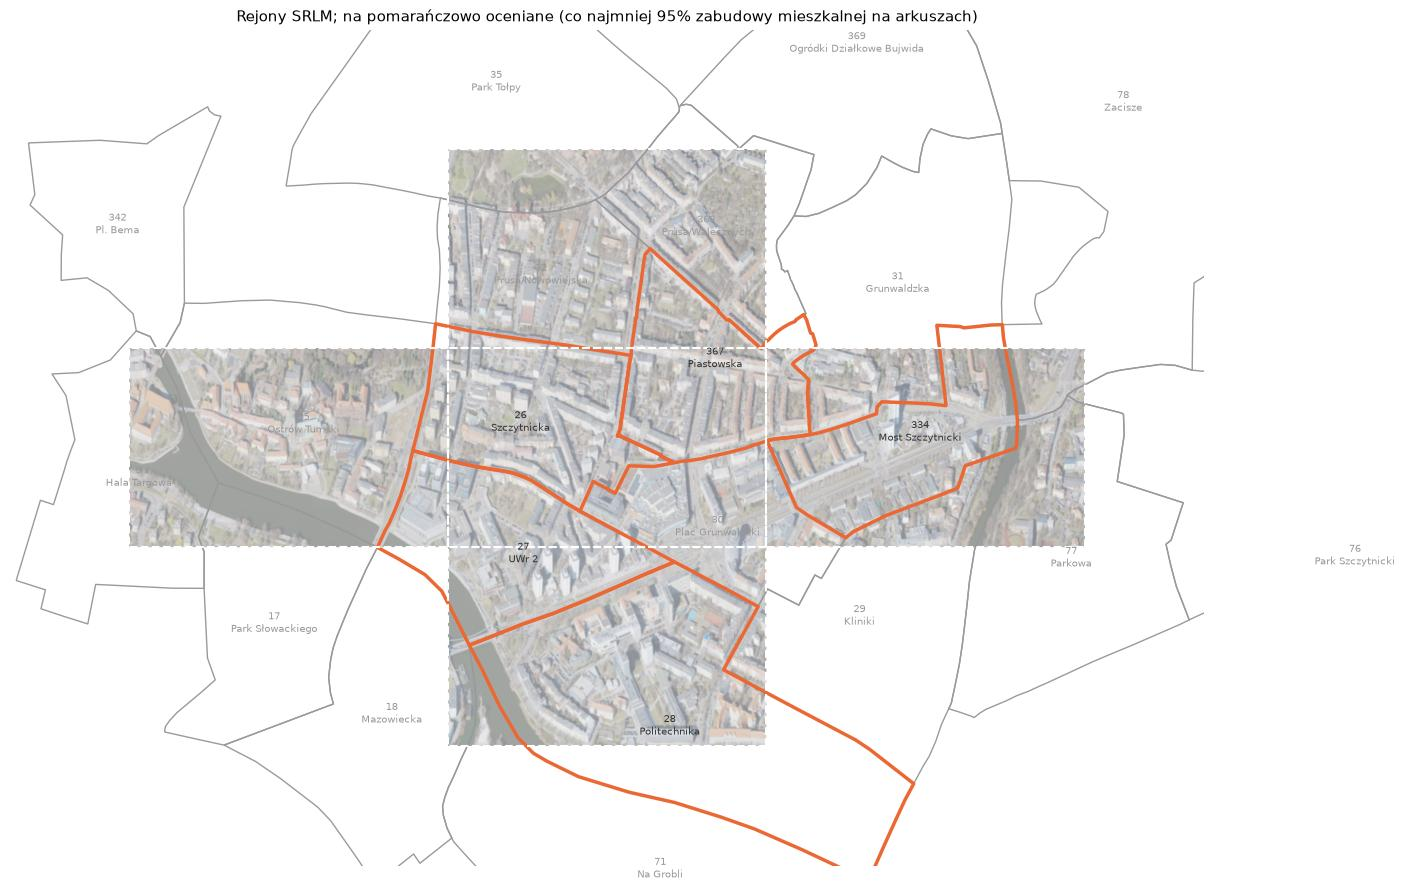

In [9]:
srlm = wczytaj_srlm()
srlm = srlm[srlm.intersects(zasieg())]
fig, ax = plt.subplots(figsize=(14, 8.8), layout="constrained")
ax.imshow(img, extent=ext, alpha=0.5)
srlm.boundary.plot(ax=ax, color=SZARY, lw=1)
srlm.loc[t.index].boundary.plot(ax=ax, color=POMARANCZ, lw=2.5)
for n, r in srlm.iterrows():
    p = r.geometry.representative_point()
    ax.text(p.x, p.y, f"{n}\n{r.nazwa}", ha="center", va="center", fontsize=7.5, color=TUSZ if n in t.index else SZARY)
for a in arkusze:
    ax.plot(*a.exterior.xy, color="white", lw=1.5, ls="--")
ax.set(xlim=(x0 - 300, x1 + 300), ylim=(y0 - 300, y1 + 300), title="Rejony SRLM; na pomarańczowo oceniane (co najmniej 95% zabudowy mieszkalnej na arkuszach)")
ax.set_axis_off()
plt.show()